In [ ]:
!zip -r unet_GLaS_mod1_outputs.zip /content/unet_GLaS_mod1_outputs

  adding: content/unet_GLaS_mod1_outputs/ (stored 0%)
  adding: content/unet_GLaS_mod1_outputs/predictions/ (stored 0%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/ (stored 0%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/testB_2_prediction.png (deflated 13%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/testB_13_prediction.png (deflated 13%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/testB_16_prediction.png (deflated 14%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/testB_5_prediction.png (deflated 13%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/testB_11_prediction.png (deflated 13%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/testB_3_prediction.png (deflated 13%)
  adding: content/unet_GLaS_mod1_outputs/predictions/visualizations/testB_6_prediction.png (deflated 14%)
  adding: content/unet_GLaS_mod1_outputs/predictions/v

In [1]:
!unzip -q /content/GLaS.zip -d /content/

In [2]:
import os
import random
import json
import shutil

import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model


IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
SEED = 42

DATASET_DIR = "/content/Warwick_QU_Dataset"


def resolve_split_dir(dataset_dir, candidates):
    for name in candidates:
        path = os.path.join(dataset_dir, name)
        if os.path.isdir(path):
            return path
    raise FileNotFoundError(
        f"Could not find any of these split directories under {dataset_dir}: {candidates}"
    )


TRAIN_SPLIT_DIR = resolve_split_dir(DATASET_DIR, ["train", "training"])
VAL_SPLIT_DIR = resolve_split_dir(DATASET_DIR, ["val", "valid", "validation"])
TEST_SPLIT_DIR = resolve_split_dir(DATASET_DIR, ["test", "testing"])

TRAIN_IMAGE_DIR = '/content/Warwick_QU_Dataset/train/img'
TRAIN_MASK_DIR = '/content/Warwick_QU_Dataset/train/mask'
VAL_IMAGE_DIR = '/content/Warwick_QU_Dataset/val/img'
VAL_MASK_DIR = '/content/Warwick_QU_Dataset/val/mask'
TEST_IMAGE_DIR = '/content/Warwick_QU_Dataset/test/img'
TEST_MASK_DIR = '/content/Warwick_QU_Dataset/test/mask'

OUTPUT_DIR = "/content/unet_GLaS_mod1_outputs"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predictions")
PREDICTION_MASK_DIR = os.path.join(PREDICTION_DIR, "masks")
PREDICTION_VIS_DIR = os.path.join(PREDICTION_DIR, "visualizations")
METRIC_DIR = os.path.join(OUTPUT_DIR, "metrics")
SPLIT_DIR = os.path.join(OUTPUT_DIR, "splits")
SNAPSHOT_DIR = os.path.join(OUTPUT_DIR, "dataset_snapshot")

for directory in [
    OUTPUT_DIR,
    MODEL_DIR,
    PLOT_DIR,
    PREDICTION_MASK_DIR,
    PREDICTION_VIS_DIR,
    METRIC_DIR,
    SPLIT_DIR,
    SNAPSHOT_DIR
]:
    os.makedirs(directory, exist_ok=True)

for split_name in ["train", "val", "test"]:
    os.makedirs(os.path.join(SNAPSHOT_DIR, split_name, "images"), exist_ok=True)
    os.makedirs(os.path.join(SNAPSHOT_DIR, split_name, "masks"), exist_ok=True)

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print("Dataset directory:", DATASET_DIR)
print("Training split:", TRAIN_SPLIT_DIR)
print("Validation split:", VAL_SPLIT_DIR)
print("Test split:", TEST_SPLIT_DIR)
print("Output directory:", OUTPUT_DIR)


Dataset directory: /content/Warwick_QU_Dataset
Training split: /content/Warwick_QU_Dataset/train
Validation split: /content/Warwick_QU_Dataset/val
Test split: /content/Warwick_QU_Dataset/test
Output directory: /content/unet_GLaS_mod1_outputs


In [3]:
def get_pairs(image_dir, mask_dir):
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    def collect_files(directory, is_mask=False):
        files = {}

        if not os.path.isdir(directory):
            raise FileNotFoundError(f"Directory not found: {directory}")

        for name in sorted(os.listdir(directory)):
            path = os.path.join(directory, name)

            if not os.path.isfile(path):
                continue

            stem, ext = os.path.splitext(name)

            if ext.lower() not in valid_extensions:
                continue

            if is_mask and stem.lower().endswith("_anno"):
                stem = stem[:-5]

            key = stem.casefold()

            if key in files:
                raise ValueError(f"Duplicate filename after normalization: {name}")

            files[key] = path

        return files

    image_files = collect_files(image_dir)
    mask_files = collect_files(mask_dir, is_mask=True)

    missing_masks = sorted(set(image_files) - set(mask_files))
    orphan_masks = sorted(set(mask_files) - set(image_files))

    if missing_masks or orphan_masks:
        raise ValueError(
            f"Image/mask pairing is incomplete.\n"
            f"Images without masks: {missing_masks[:10]}\n"
            f"Masks without images: {orphan_masks[:10]}"
        )

    return [
        (image_files[key], mask_files[key])
        for key in sorted(image_files)
    ]


def load_image_mask(img_path, mask_path):
    img = cv2.imread(img_path.decode(), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Could not read image: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
    img = img.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path.decode(), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    return img, mask


def tf_load_image_mask(img_path, mask_path):
    img, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    img.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return img, mask


def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, k)
    mask = tf.image.rot90(mask, k)

    return image, mask


train_pairs = get_pairs(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
val_pairs = get_pairs(VAL_IMAGE_DIR, VAL_MASK_DIR)
test_pairs = get_pairs(TEST_IMAGE_DIR, TEST_MASK_DIR)
pairs = train_pairs + val_pairs + test_pairs

if not train_pairs:
    raise ValueError("No training image-mask pairs were found.")
if not val_pairs:
    raise ValueError("No validation image-mask pairs were found.")
if not test_pairs:
    raise ValueError("No test image-mask pairs were found.")

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))
print("Total paired samples:", len(pairs))

for split_name, split_pairs in [
    ("train", train_pairs),
    ("val", val_pairs),
    ("test", test_pairs)
]:
    image_snapshot_dir = os.path.join(SNAPSHOT_DIR, split_name, "images")
    mask_snapshot_dir = os.path.join(SNAPSHOT_DIR, split_name, "masks")

    for img_path, mask_path in split_pairs:
        shutil.copy2(img_path, os.path.join(image_snapshot_dir, os.path.basename(img_path)))
        shutil.copy2(mask_path, os.path.join(mask_snapshot_dir, os.path.basename(mask_path)))

def make_dataset(sample_pairs, training=False):
    img_paths = [pair[0] for pair in sample_pairs]
    mask_paths = [pair[1] for pair in sample_pairs]

    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    if training:
        ds = ds.shuffle(
            buffer_size=len(sample_pairs),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(tf_load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
test_ds = make_dataset(test_pairs, training=False)

print("Train samples:", len(train_pairs))
print("Validation samples:", len(val_pairs))
print("Test samples:", len(test_pairs))
print("Total samples:", len(pairs))

split_rows = []
for split_name, split_pairs in [
    ("train", train_pairs),
    ("validation", val_pairs),
    ("test", test_pairs)
]:
    for img_path, mask_path in split_pairs:
        split_rows.append({
            "split": split_name,
            "image_path": img_path,
            "mask_path": mask_path,
            "image_filename": os.path.basename(img_path),
            "mask_filename": os.path.basename(mask_path)
        })

pd.DataFrame(split_rows).to_csv(
    os.path.join(SPLIT_DIR, "split_manifest.csv"),
    index=False
)

split_counts = {
    "total": len(pairs),
    "train": len(train_pairs),
    "validation": len(val_pairs),
    "test": len(test_pairs),
    "source": "explicit_dataset_directories"
}

with open(os.path.join(SPLIT_DIR, "split_counts.json"), "w") as file:
    json.dump(split_counts, file, indent=4)



Training pairs: 133
Validation pairs: 16
Test pairs: 16
Total paired samples: 165
Train samples: 133
Validation samples: 16
Test samples: 16
Total samples: 165


In [4]:
def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x


def down_block(x, filters):
    c = conv_block(x, filters)
    p = layers.MaxPool2D((2, 2))(c)
    p = layers.Dropout(0.2)(p)
    return c, p


def resize_to_ref(tensor, ref, name=None):
    return layers.Lambda(
        lambda t: tf.image.resize(t[0], tf.shape(t[1])[1:3], method="bilinear"),
        name=name
    )([tensor, ref])


def project_and_resize(skip, ref, filters):
    skip = layers.Conv2D(filters, 1, padding="same", kernel_initializer="he_normal")(skip)
    skip = layers.BatchNormalization()(skip)
    skip = layers.ReLU()(skip)
    skip = resize_to_ref(skip, ref)
    return skip


def up_block(x, skips, filters):
    x = layers.UpSampling2D((2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    fused = [x]

    for skip_tensor in skips:
        if skip_tensor is not None:
            skip_tensor = project_and_resize(skip_tensor, x, filters)
            fused.append(skip_tensor)

    if len(fused) > 1:
        x = layers.Concatenate()(fused)

    x = layers.Dropout(0.2)(x)
    x = conv_block(x, filters)
    return x


def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    c1, p1 = down_block(inputs, 32)
    c2, p2 = down_block(p1, 64)
    c3, p3 = down_block(p2, 128)
    c4, p4 = down_block(p3, 256)

    bottleneck = conv_block(p4, 512)

    u1 = up_block(bottleneck, [c4], 256)
    u2 = up_block(u1, [c3, c4], 128)
    u3 = up_block(u2, [c2, c3], 64)
    u4 = up_block(u3, [c1, c2], 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(u4)

    model = Model(inputs, outputs, name="UNet_MultiSkip_Resized")
    return model


model = build_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=[
        "accuracy",
        dice_coef,
        iou_coef,
        tf.keras.metrics.Precision(name="precision", thresholds=0.5),
        tf.keras.metrics.Recall(name="recall", thresholds=0.5)
    ]
)

summary_lines = []
model.summary(print_fn=lambda line: summary_lines.append(line))
with open(os.path.join(MODEL_DIR, "model_summary.txt"), "w") as file:
    file.write("\n".join(summary_lines))

model.summary()
print("Model parameters:", model.count_params())

Model: "UNet_MultiSkip_Resized"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 128,  │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_1[

 Total params: 8,971,297 (34.22 MB)

 Trainable params: 8,963,041 (34.19 MB)

 Non-trainable params: 8,256 (32.25 KB)

Model parameters: 8971297


In [5]:
best_model_path = os.path.join(MODEL_DIR, "best_unet.keras")
final_model_path = os.path.join(MODEL_DIR, "final_unet.keras")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        best_model_path,
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

model.save(final_model_path)

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(
    os.path.join(METRIC_DIR, "training_history.csv"),
    index=False
)

Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 757ms/step - accuracy: 0.6168 - dice_coef: 0.5627 - iou_coef: 0.3954 - loss: 0.4373 - precision: 0.6252 - recall: 0.6147
Epoch 1: val_dice_coef improved from None to 0.45779, saving model to /content/unet_GLaS_mod1_outputs/models/best_unet.keras

Epoch 1: finished saving model to /content/unet_GLaS_mod1_outputs/models/best_unet.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 122s 859ms/step - accuracy: 0.6689 - dice_coef: 0.6079 - iou_coef: 0.4424 - loss: 0.3925 - precision: 0.6631 - recall: 0.7019 - val_accuracy: 0.5977 - val_dice_coef: 0.4578 - val_iou_coef: 0.3023 - val_loss: 0.5422 - val_precision: 0.6362 - val_recall: 0.3939 - learning_rate: 1.0000e-04
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.7128 - dice_coef: 0.6818 - iou_coef: 0.5236 - loss: 0.3182 - precision: 0.6991 - recall: 0.7845
Epoch 2: val_dice_coef did not improve from 0.45779
67/67 ━━━━━━━━━━━━━━━━━━━━ 9s 133ms/step - accuracy: 0.7200 - dice_coef: 0.6871 - iou_coef: 0.

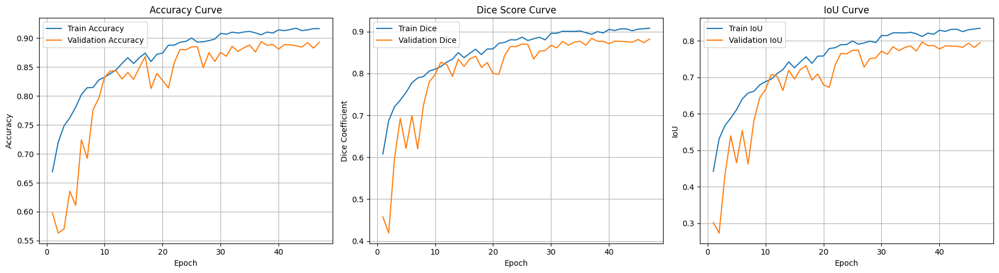

In [6]:
def plot_training_curves(training_history):
    hist = training_history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, hist["accuracy"], label="Train Accuracy")
    plt.plot(epochs_range, hist["val_accuracy"], label="Validation Accuracy")
    plt.title("Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, hist["dice_coef"], label="Train Dice")
    plt.plot(epochs_range, hist["val_dice_coef"], label="Validation Dice")
    plt.title("Dice Score Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Dice Coefficient")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, hist["iou_coef"], label="Train IoU")
    plt.plot(epochs_range, hist["val_iou_coef"], label="Validation IoU")
    plt.title("IoU Curve")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOT_DIR, "training_curves.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


plot_training_curves(history)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.8707 - dice_coef: 0.8853 - iou_coef: 0.7975 - loss: 0.1147 - precision: 0.8384 - recall: 0.9438
Final test results:
accuracy: 0.8707
dice_coef: 0.8853
iou_coef: 0.7975
loss: 0.1147
precision: 0.8384
recall: 0.9438


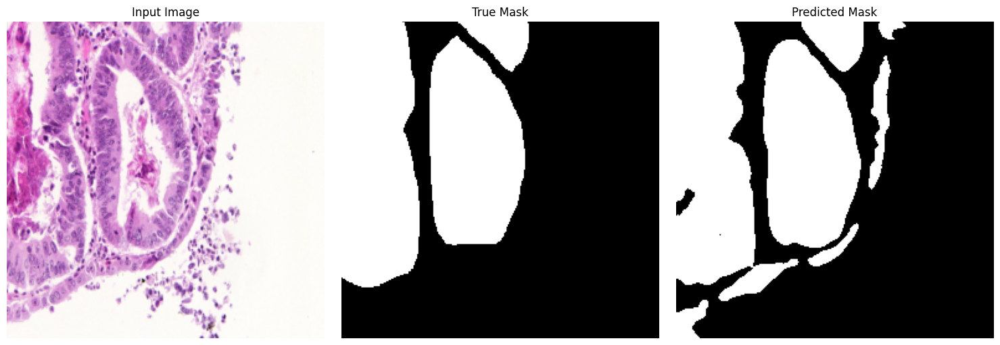

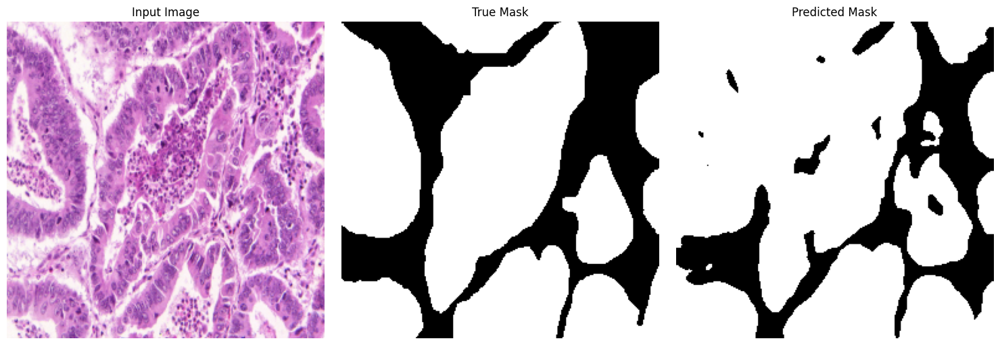

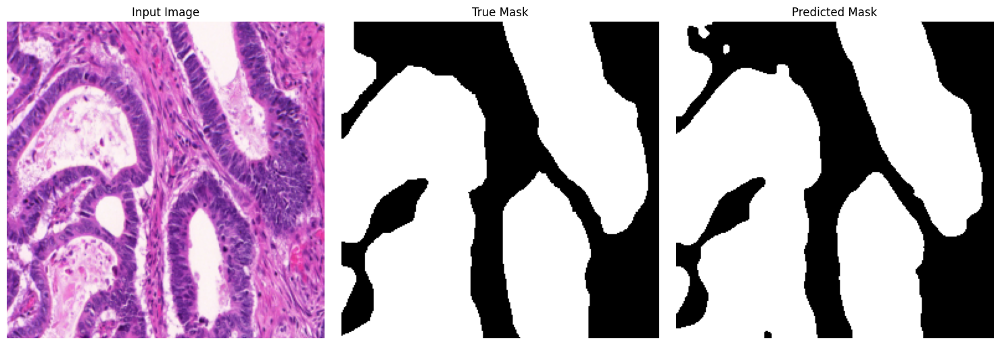

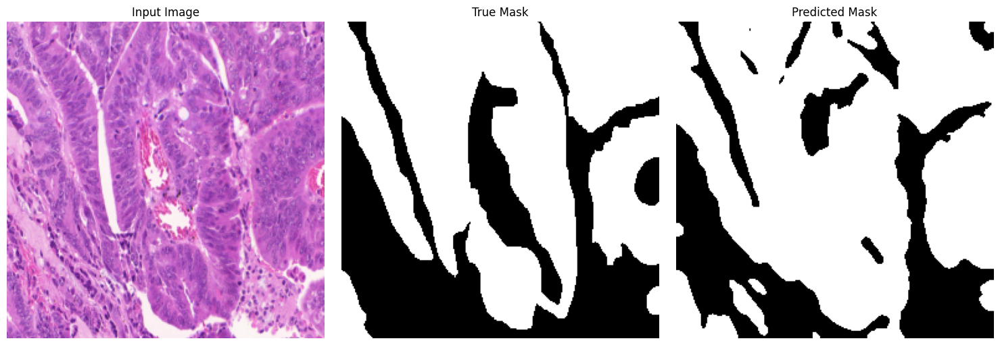

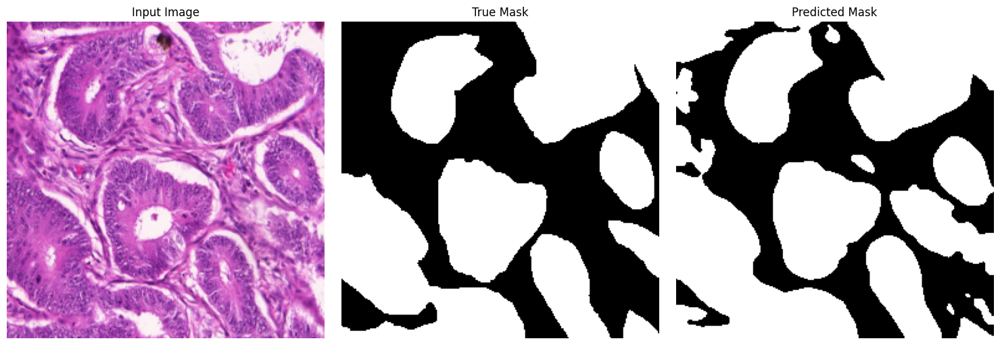

...

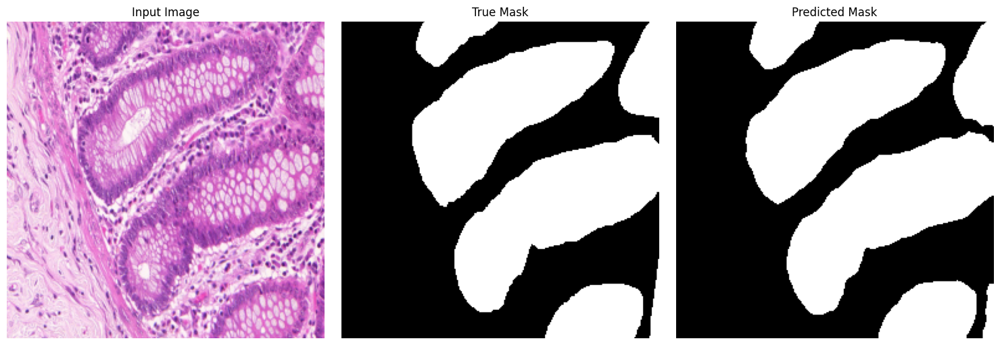

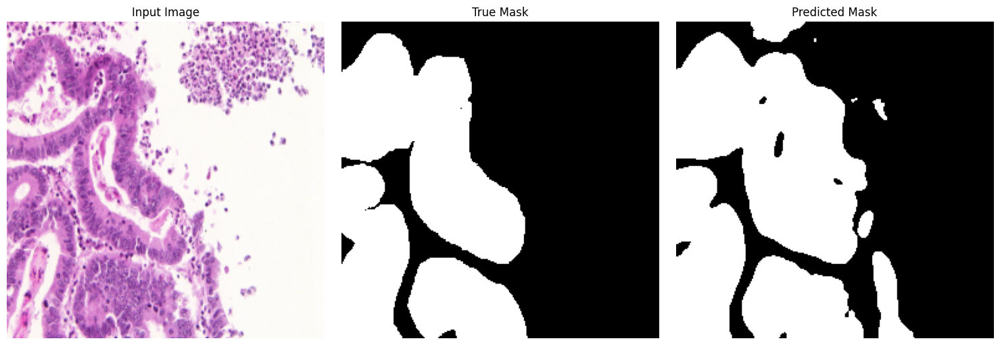

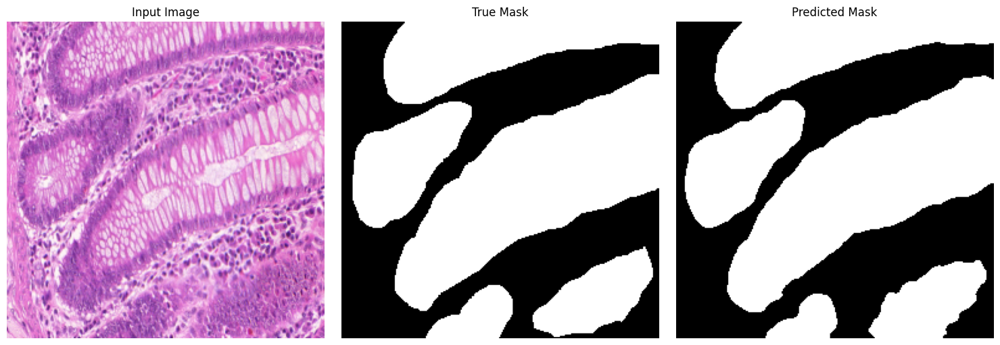

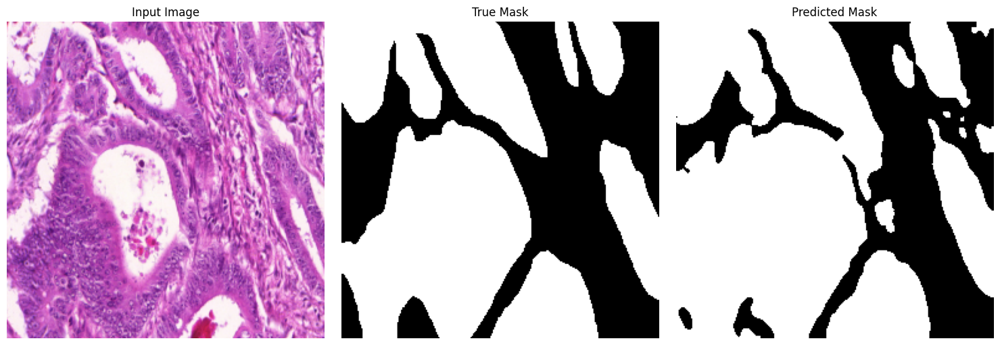

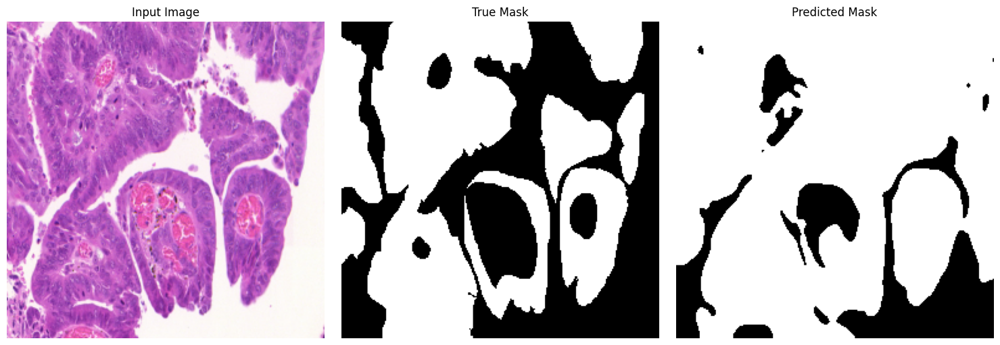

Per-sample test metrics:


,image,dice,iou,precision,recall
0,testB_1.png,0.918083,0.848571,0.879073,0.960716
1,testB_10.png,0.880480,0.786479,0.812053,0.961499
2,testB_11.png,0.975333,0.951854,0.968297,0.982473
3,testB_12.png,0.886377,0.795940,0.832341,0.947916
4,testB_13.png,0.890403,0.802455,0.837432,0.950526
5,testB_14.png,0.780066,0.639432,0.899510,0.688624
6,testB_15.png,0.786459,0.648070,0.668861,0.954231
7,testB_16.png,0.832285,0.712747,0.752880,0.930414
8,testB_2.png,0.883839,0.791857,0.813012,0.968185
9,testB_3.png,0.978136,0.957208,0.971888,0.984465


In [7]:
test_results = model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

test_results = {key: float(value) for key, value in test_results.items()}

with open(os.path.join(METRIC_DIR, "test_metrics.json"), "w") as file:
    json.dump(test_results, file, indent=4)

print("Final test results:")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")


def show_prediction(model, pair, save_path=None):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    true_binary = mask.squeeze().astype(np.uint8)
    pred_binary = pred_mask.squeeze().astype(np.uint8)
    intersection = np.logical_and(true_binary, pred_binary).sum()
    dice = (2.0 * intersection + 1e-7) / (
        true_binary.sum() + pred_binary.sum() + 1e-7
    )
    union = np.logical_or(true_binary, pred_binary).sum()
    iou = (intersection + 1e-7) / (union + 1e-7)

    # Pixel-wise precision and recall using the same 0.5 prediction threshold.
    true_positive = intersection
    false_positive = np.logical_and(true_binary == 0, pred_binary == 1).sum()
    false_negative = np.logical_and(true_binary == 1, pred_binary == 0).sum()

    precision = (
        true_positive / (true_positive + false_positive)
        if (true_positive + false_positive) > 0 else 0.0
    )
    recall = (
        true_positive / (true_positive + false_negative)
        if (true_positive + false_negative) > 0 else 0.0
    )

    return dice, iou, precision, recall, pred_mask


per_sample_results = []

for index, pair in enumerate(test_pairs, start=1):
    image_name = os.path.basename(pair[0])
    image_stem = os.path.splitext(image_name)[0]
    visualization_path = os.path.join(
        PREDICTION_VIS_DIR,
        f"{image_stem}_prediction.png"
    )
    mask_path = os.path.join(
        PREDICTION_MASK_DIR,
        f"{image_stem}_predicted_mask.png"
    )

    dice, iou, precision, recall, predicted_mask = show_prediction(
        model,
        pair,
        save_path=visualization_path
    )

    cv2.imwrite(mask_path, predicted_mask.squeeze() * 255)

    per_sample_results.append({
        "image": image_name,
        "dice": float(dice),
        "iou": float(iou),
        "precision": float(precision),
        "recall": float(recall)
    })

per_sample_df = pd.DataFrame(per_sample_results)
per_sample_df.to_csv(
    os.path.join(METRIC_DIR, "per_sample_test_metrics.csv"),
    index=False
)

print("Per-sample test metrics:")
display(per_sample_df)

In [8]:
experiment_summary = {
    "model_name": model.name,
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history.history["loss"]),
    "seed": SEED,
    "total_samples": len(pairs),
    "train_samples": len(train_pairs),
    "validation_samples": len(val_pairs),
    "test_samples": len(test_pairs),
    "best_validation_dice": float(max(history.history["val_dice_coef"])),
    "test_metrics": test_results,
    "output_directory": OUTPUT_DIR
}

with open(os.path.join(OUTPUT_DIR, "experiment_summary.json"), "w") as file:
    json.dump(experiment_summary, file, indent=4)

readme_text = (
    "Rock segmentation experiment outputs\n"
    "\n"
    "models/: best and final Keras models plus model summary\n"
    "plots/: training curves\n"
    "predictions/masks/: predicted binary test masks\n"
    "predictions/visualizations/: input, ground-truth and predicted-mask comparisons\n"
    "metrics/: training history (including precision/recall), aggregate test metrics (including precision/recall) and per-sample test metrics\n"
    "splits/: train, validation and test split manifest and counts\n"
    "dataset_snapshot/: copies of the paired source images and masks\n"
)

with open(os.path.join(OUTPUT_DIR, "README.txt"), "w") as file:
    file.write(readme_text)

print("All experiment files saved to:", OUTPUT_DIR)

All experiment files saved to: /content/unet_GLaS_mod1_outputs
